<a href="https://colab.research.google.com/github/paganinigor0807/tech-challenge-fase4/blob/develop/notebooks/processamento_EDA_bases.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Olist E-Commerce — Preparação da Base e Análise Exploratória (EDA)

### Voice of Customer Intelligence com RAG

Este notebook une os dois estudos feitos:

1. **Preparação e limpeza da base** (merge robusto entre as tabelas do Olist, com validação de
   integridade, tratamento de nulos documentado e geração dos arquivos que vão alimentar o RAG).
2. **Análise exploratória** (negócio + texto das avaliações) sobre a base já tratada, terminando em
   decisões concretas para a etapa de construção do pipeline RAG.

**Estrutura:**
1. Setup
2. Qualidade dos dados brutos (diagnóstico antes de qualquer tratamento)
3. Preparação e limpeza — tabela por tabela
4. Merge validado e enriquecimento com categoria do produto
5. Texto da avaliação e tratamento final → geração de `base_avaliacoes_completa.csv` e `base_rag.csv`
6. EDA de negócio (sobre a base tratada)
7. EDA textual das reviews (sobre a base do RAG)
8. Conclusões e decisões para o RAG


## 1. Setup

In [ ]:
from pathlib import Path
import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from wordcloud import WordCloud

PASTA_RAW = Path("data/raw")            # CSVs baixados do Kaggle
PASTA_PROCESSED = Path("data/processed")  # saídas deste notebook
PASTA_PROCESSED.mkdir(parents=True, exist_ok=True)

MIN_CHARS_COMENTARIO = 5    # comentários com menos caracteres que isso são tratados como "sem comentário"
DEDUP_TEXTOS_RAG = True     # remove textos idênticos na base do RAG (guardando a contagem em n_ocorrencias)

log = {}  # registro de tudo o que foi removido/tratado (útil para justificar no README)

pd.options.display.float_format = '{:,.2f}'.format
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

print("Setup pronto.")


Setup pronto.


## 2. Qualidade dos dados brutos

Diagnóstico de todas as tabelas **antes** de qualquer tratamento: nulos, duplicatas e
inconsistências lógicas. Isso justifica, com números reais, cada decisão de limpeza da Seção 3.

In [ ]:
reviews     = pd.read_csv(PASTA_RAW / "olist_order_reviews_dataset.csv")
orders      = pd.read_csv(PASTA_RAW / "olist_orders_dataset.csv")
customers   = pd.read_csv(PASTA_RAW / "olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
geolocation = pd.read_csv(PASTA_RAW / "olist_geolocation_dataset.csv", dtype={"geolocation_zip_code_prefix": str})
products    = pd.read_csv(PASTA_RAW / "olist_products_dataset.csv")
itens_raw   = pd.read_csv(PASTA_RAW / "olist_order_items_dataset.csv")
payments    = pd.read_csv(PASTA_RAW / "olist_order_payments_dataset.csv")
sellers     = pd.read_csv(PASTA_RAW / "olist_sellers_dataset.csv")

tabelas = {
    "reviews": reviews, "orders": orders, "customers": customers, "geolocation": geolocation,
    "products": products, "order_items": itens_raw, "order_payments": payments, "sellers": sellers,
}

def diagnostico(nome, df):
    print("=" * 72)
    print(f"{nome}: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
    print(f"  linhas 100% duplicadas: {df.duplicated().sum():,}")
    nulos = df.isna().sum()
    nulos = nulos[nulos > 0]
    if len(nulos):
        print("  nulos por coluna:")
        for col, n in nulos.items():
            print(f"    {col:35s} {n:>9,}  ({n / len(df):.1%})")
    else:
        print("  sem valores nulos")

for nome, df in tabelas.items():
    diagnostico(nome, df)


reviews: 99,224 linhas x 7 colunas
  linhas 100% duplicadas: 0
  nulos por coluna:
    review_comment_title                   87,656  (88.3%)
    review_comment_message                 58,247  (58.7%)
orders: 99,441 linhas x 8 colunas


  linhas 100% duplicadas: 0
  nulos por coluna:
    order_approved_at                         160  (0.2%)
    order_delivered_carrier_date            1,783  (1.8%)
    order_delivered_customer_date           2,965  (3.0%)
customers: 99,441 linhas x 5 colunas
  linhas 100% duplicadas: 0
  sem valores nulos
geolocation: 1,000,163 linhas x 5 colunas


  linhas 100% duplicadas: 261,831
  sem valores nulos
products: 32,951 linhas x 9 colunas
  linhas 100% duplicadas: 0
  nulos por coluna:
    product_category_name                     610  (1.9%)
    product_name_lenght                       610  (1.9%)
    product_description_lenght                610  (1.9%)
    product_photos_qty                        610  (1.9%)
    product_weight_g                            2  (0.0%)
    product_length_cm                           2  (0.0%)
    product_height_cm                           2  (0.0%)
    product_width_cm                            2  (0.0%)
order_items: 112,650 linhas x 7 colunas


  linhas 100% duplicadas: 0
  sem valores nulos
order_payments: 103,886 linhas x 5 colunas
  linhas 100% duplicadas: 0
  sem valores nulos
sellers: 3,095 linhas x 4 colunas
  linhas 100% duplicadas: 0
  sem valores nulos


In [ ]:
# Inconsistências lógicas adicionais, antes da limpeza
orders_check = orders.copy()
for c in ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_approved_at']:
    orders_check[c] = pd.to_datetime(orders_check[c], errors='coerce')

entrega_antes_compra = (orders_check['order_delivered_customer_date'] < orders_check['order_purchase_timestamp']).sum()
score_invalido = (~reviews['review_score'].between(1, 5)).sum()
preco_invalido = (itens_raw['price'] <= 0).sum()
pedidos_com_varias_reviews = reviews['order_id'].duplicated(keep=False).sum()

print(f"Pedidos com entrega registrada ANTES da compra: {entrega_antes_compra}")
print(f"Reviews com score fora de 1-5: {score_invalido}")
print(f"Itens com preço <= 0: {preco_invalido}")
print(f"Linhas de review em pedidos com mais de uma avaliação: {pedidos_com_varias_reviews}")


Pedidos com entrega registrada ANTES da compra: 0
Reviews com score fora de 1-5: 0
Itens com preço <= 0: 0
Linhas de review em pedidos com mais de uma avaliação: 1098


**Leitura do diagnóstico:** nenhuma inconsistência grave de data/preço/nota. O ponto que mais
exige tratamento é a tabela `geolocation` (muitas linhas por CEP, inclusive duplicatas exatas) e o
alto volume de nulos em `review_comment_title`/`message`, esperado, já que a maioria dos clientes só
dá a nota sem escrever texto. A Seção 3 trata cada um desses pontos de forma explícita.

## 3. Preparação e limpeza — tabela por tabela

### 3.1 `reviews` (a tabela central)

Decisões:
- **Duplicatas exatas** são removidas.
- **Um pedido pode ter mais de uma avaliação** (e o `review_id` também se repete entre pedidos).
  Mantemos **a avaliação mais recente de cada `order_id`**, o que deixa `order_id` como chave única,
  evita que a mesma review apareça mais de uma vez na base vetorial do RAG.
- **Nulos em título e mensagem são esperados** (cliente só deu a nota). Não são removidos aqui: viram
  texto vazio na base completa; só a base do RAG filtra por comentário (Seção 5).
- Textos têm quebras de linha e espaços repetidos normalizados.

In [ ]:
n0 = len(reviews)
reviews = reviews.drop_duplicates()
log["reviews: linhas 100% duplicadas removidas"] = n0 - len(reviews)

for col in ["review_creation_date", "review_answer_timestamp"]:
    reviews[col] = pd.to_datetime(reviews[col], errors="coerce")

n0 = len(reviews)
reviews = reviews[reviews["review_score"].between(1, 5)]
log["reviews: notas fora de 1-5 removidas"] = n0 - len(reviews)

def limpar_texto_bruto(serie):
    """Nulo vira string vazia; quebras de linha/tabs e espaços repetidos viram um espaço só."""
    return (serie.fillna("").astype(str)
            .str.replace(r"[\r\n\t]+", " ", regex=True)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip())

log["reviews: títulos nulos (viraram vazio)"] = int(reviews["review_comment_title"].isna().sum())
log["reviews: mensagens nulas (viraram vazio)"] = int(reviews["review_comment_message"].isna().sum())
reviews["review_comment_title"] = limpar_texto_bruto(reviews["review_comment_title"])
reviews["review_comment_message"] = limpar_texto_bruto(reviews["review_comment_message"])

reviews = reviews.sort_values(["order_id", "review_answer_timestamp", "review_creation_date"],
                              na_position="first")
n0 = len(reviews)
reviews = reviews.drop_duplicates(subset="order_id", keep="last")
log["reviews: avaliações antigas de pedidos com mais de uma avaliação"] = n0 - len(reviews)

assert reviews["order_id"].is_unique
print(f"reviews limpa: {len(reviews):,} linhas (uma por pedido)")


reviews limpa: 98,673 linhas (uma por pedido)


### 3.2 `orders`

Os nulos em `order_approved_at`, `order_delivered_carrier_date` e `order_delivered_customer_date`
**não são erro**: representam pedidos cancelados, indisponíveis ou ainda não entregues. Por isso
**não são imputados** (inventar uma data distorceria os indicadores). Criamos variáveis derivadas de
entrega, que servem como metadados para perguntas sobre atraso.

In [ ]:
n0 = len(orders)
orders = orders.drop_duplicates(subset="order_id")
log["orders: pedidos duplicados removidos"] = n0 - len(orders)

colunas_data = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
for col in colunas_data:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

dia = pd.Timedelta(days=1)
orders["tempo_entrega_dias"] = (orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]) / dia
orders["dias_atraso"] = (orders["order_delivered_customer_date"] - orders["order_estimated_delivery_date"]) / dia
orders["entregue_com_atraso"] = (orders["dias_atraso"] > 0).where(orders["dias_atraso"].notna()).astype("boolean")

print(f"orders limpa: {len(orders):,} linhas")
print("\nStatus dos pedidos:")
print(orders["order_status"].value_counts().to_string())


orders limpa: 99,441 linhas

Status dos pedidos:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2


### 3.3 `customers`

`customer_id` é único por pedido; `customer_unique_id` se repete (mesmo cliente comprando mais de uma
vez), isso é legítimo e **não é duplicata**.

In [ ]:
n0 = len(customers)
customers = customers.drop_duplicates(subset="customer_id")
log["customers: customer_id duplicados removidos"] = n0 - len(customers)

customers["customer_zip_code_prefix"] = customers["customer_zip_code_prefix"].str.zfill(5)
customers["customer_city"] = customers["customer_city"].str.strip().str.lower()
customers["customer_state"] = customers["customer_state"].str.strip().str.upper()

print(f"customers limpa: {len(customers):,} linhas")


customers limpa: 99,441 linhas


### 3.4 `geolocation`

Esta tabela tem **muitas linhas por CEP** (várias coordenadas para o mesmo prefixo) e algumas
coordenadas fora do Brasil. Para que a junção **não multiplique linhas**, fazemos:
1. remover duplicatas exatas;
2. descartar coordenadas fora do retângulo geográfico do Brasil;
3. **agregar por CEP**: mediana de latitude/longitude (robusta a outliers) e cidade/estado mais frequentes.

O resultado tem exatamente uma linha por `zip_code_prefix`.

In [ ]:
geolocation = geolocation.copy()
n0 = len(geolocation)
geolocation = geolocation.drop_duplicates()
log["geolocation: linhas 100% duplicadas removidas"] = n0 - len(geolocation)

geolocation["geolocation_zip_code_prefix"] = geolocation["geolocation_zip_code_prefix"].str.zfill(5)

dentro_do_brasil = (geolocation["geolocation_lat"].between(-34, 6)
                    & geolocation["geolocation_lng"].between(-74, -34))
log["geolocation: coordenadas fora do Brasil removidas"] = int((~dentro_do_brasil).sum())
geolocation = geolocation[dentro_do_brasil]

def moda(serie):
    m = serie.mode()
    return m.iat[0] if len(m) else np.nan

geo_cep = (geolocation.groupby("geolocation_zip_code_prefix")
           .agg(geo_lat=("geolocation_lat", "median"),
                geo_lng=("geolocation_lng", "median"),
                geo_city=("geolocation_city", moda),
                geo_state=("geolocation_state", moda))
           .reset_index())

assert geo_cep["geolocation_zip_code_prefix"].is_unique
print(f"geolocation agregada: {len(geo_cep):,} CEPs únicos")


geolocation agregada: 19,010 CEPs únicos


### 3.5 `products`

Só duas colunas interessam para o RAG (`product_id` e a categoria). Categoria nula vira
`"sem_categoria"` (rótulo explícito é melhor que deixar nulo, porque permite filtrar e contar). As
medidas físicas (peso, dimensões) não entram na base final.

In [ ]:
n0 = len(products)
products = products.drop_duplicates(subset="product_id")
log["products: product_id duplicados removidos"] = n0 - len(products)

log["products: categoria nula (virou 'sem_categoria')"] = int(products["product_category_name"].isna().sum())
products["product_category_name"] = products["product_category_name"].fillna("sem_categoria")

print(f"products limpa: {len(products):,} linhas")


products limpa: 32,951 linhas


## 4. Merge validado e enriquecimento com categoria do produto

Todas as junções são `left` a partir de `reviews` (cada avaliação deve continuar existindo) e usam
`validate=` para **garantir que nenhuma linha foi multiplicada** por chave repetida.

In [ ]:
n_reviews = len(reviews)

base = reviews.merge(orders, on="order_id", how="left", validate="one_to_one")
base = base.merge(customers, on="customer_id", how="left", validate="many_to_one")
base = base.merge(geo_cep, left_on="customer_zip_code_prefix",
                  right_on="geolocation_zip_code_prefix", how="left", validate="many_to_one")
base = base.drop(columns=["geolocation_zip_code_prefix"])

assert len(base) == n_reviews, "o merge alterou o número de linhas!"
assert base["order_id"].is_unique

print(f"base após merge: {len(base):,} linhas x {base.shape[1]} colunas")
print(f"avaliações sem pedido correspondente em orders: {base['order_status'].isna().sum():,}")
print(f"avaliações sem coordenadas (CEP não encontrado em geolocation): {base['geo_lat'].isna().sum():,}")


base após merge: 98,673 linhas x 25 colunas
avaliações sem pedido correspondente em orders: 0
avaliações sem coordenadas (CEP não encontrado em geolocation): 277


A categoria é o metadado mais útil para o desafio adicional. Como um pedido pode ter **vários itens de categorias diferentes**, agregamos por
pedido: `categoria_principal` (a mais frequente), `categorias` (todas) e `n_itens`.

In [ ]:
itens = itens_raw.copy()
n0 = len(itens)
itens = itens.drop_duplicates()
log["order_items: linhas 100% duplicadas removidas"] = n0 - len(itens)

itens = itens.merge(products[["product_id", "product_category_name"]],
                    on="product_id", how="left", validate="many_to_one")

log["order_items: itens sem categoria (viraram 'sem_categoria')"] = int(itens["product_category_name"].isna().sum())
itens["product_category_name"] = itens["product_category_name"].fillna("sem_categoria")

por_pedido = (itens.groupby("order_id")
              .agg(n_itens=("order_item_id", "count"),
                   valor_itens=("price", "sum"),
                   valor_frete=("freight_value", "sum"),
                   categoria_principal=("product_category_name", moda),
                   categorias=("product_category_name", lambda s: " | ".join(sorted(set(s)))))
              .reset_index())

base = base.merge(por_pedido, on="order_id", how="left", validate="one_to_one")

for col in ["categoria_principal", "categorias"]:
    base[col] = base[col].fillna("sem_itens")

assert len(base) == n_reviews, "o merge com order_items alterou o número de linhas!"

print(f"categoria adicionada. Pedidos sem itens registrados: {(base['categoria_principal'] == 'sem_itens').sum():,}")
print("\nTop 10 categorias principais:")
print(base["categoria_principal"].value_counts().head(10).to_string())


categoria adicionada. Pedidos sem itens registrados: 756

Top 10 categorias principais:
categoria_principal
cama_mesa_banho           9268
beleza_saude              8760
esporte_lazer             7632
informatica_acessorios    6619
moveis_decoracao          6273
utilidades_domesticas     5739
relogios_presentes        5540
telefonia                 4144
automotivo                3871
brinquedos                3833


In [ ]:
assert len(base) == n_reviews
print(f"base final: {len(base):,} linhas x {base.shape[1]} colunas")


base final: 98,673 linhas x 30 colunas


## 5. Texto da avaliação e tratamento final

- `texto_avaliacao` = título + mensagem (quando os dois existem). o campo que será embutido no RAG.
- `tem_comentario` = o texto tem ao menos `MIN_CHARS_COMENTARIO` caracteres.
- Colunas categóricas restantes com nulo recebem um rótulo explícito; **coordenadas ausentes ficam
  nulas** (não faz sentido inventar latitude).

In [ ]:
def juntar(titulo, mensagem):
    if titulo and mensagem:
        return f"{titulo}. {mensagem}"
    return titulo or mensagem

base["texto_avaliacao"] = [juntar(t, m) for t, m in
                           zip(base["review_comment_title"], base["review_comment_message"])]
base["tem_comentario"] = base["texto_avaliacao"].str.len() >= MIN_CHARS_COMENTARIO

for col in ["order_status", "customer_city", "customer_state"]:
    base[col] = base[col].fillna("desconhecido")

log["base: avaliações com comentário utilizável"] = int(base["tem_comentario"].sum())
log["base: avaliações só com nota (sem comentário)"] = int((~base["tem_comentario"]).sum())

print(f"com comentário: {base['tem_comentario'].sum():,} ({base['tem_comentario'].mean():.1%})")
print("\nDistribuição das notas (todas as avaliações):")
print(base["review_score"].value_counts().sort_index().to_string())


com comentário: 41,497 (42.1%)

Distribuição das notas (todas as avaliações):
review_score
1    11363
2     3131
3     8133
4    19038
5    57008


### Base do RAG

Só entram avaliações **com comentário**. Muitos comentários curtos se repetem literalmente
("Ótimo", "Recomendo"), o que encheria o top-k de recuperação com o mesmo texto, por isso removemos
textos idênticos (comparando em minúsculas e sem pontuação) e **guardamos a frequência em
`n_ocorrencias`**, para não perder essa informação. Para desligar essa deduplicação, use
`DEDUP_TEXTOS_RAG = False` no setup.

In [ ]:
rag = base[base["tem_comentario"]].copy()

rag["texto_norm"] = (rag["texto_avaliacao"].str.lower()
                     .str.replace(r"[^\w\s]", "", regex=True)
                     .str.replace(r"\s+", " ", regex=True)
                     .str.strip())
rag["n_ocorrencias"] = rag.groupby("texto_norm")["order_id"].transform("size")

if DEDUP_TEXTOS_RAG:
    n0 = len(rag)
    rag = rag.sort_values("review_creation_date").drop_duplicates(subset="texto_norm", keep="last")
    log["rag: textos idênticos removidos (frequência guardada em n_ocorrencias)"] = n0 - len(rag)

rag["doc_id"] = rag["order_id"]  # order_id é único na base; review_id NÃO é

colunas_rag = [
    "doc_id", "review_id", "order_id", "texto_avaliacao", "review_score", "review_creation_date",
    "n_ocorrencias", "order_status", "order_purchase_timestamp", "tempo_entrega_dias", "dias_atraso",
    "entregue_com_atraso", "customer_state", "customer_city", "geo_lat", "geo_lng",
    "categoria_principal", "categorias", "n_itens",
]
colunas_rag = [c for c in colunas_rag if c in rag.columns]
rag = rag[colunas_rag].rename(columns={"review_score": "nota", "texto_avaliacao": "texto",
                                       "review_creation_date": "data_avaliacao",
                                       "order_purchase_timestamp": "data_compra"})
rag = rag.reset_index(drop=True)

assert rag["doc_id"].is_unique
print(f"base do RAG: {len(rag):,} documentos")
print("\nTamanho dos textos (caracteres):")
print(rag["texto"].str.len().describe().round(0).to_string())
rag.head(3)


base do RAG: 35,027 documentos

Tamanho dos textos (caracteres):
count   35,027.00
mean        81.00
std         53.00
min          5.00
25%         40.00
50%         65.00
75%        108.00
max        229.00


,doc_id,review_id,order_id,texto,nota,data_avaliacao,n_ocorrencias,order_status,data_compra,tempo_entrega_dias,dias_atraso,entregue_com_atraso,customer_state,customer_city,geo_lat,geo_lng,categoria_principal,categorias,n_itens
0,809a282bbd5dbcabb6f2f724fca862ec,69ac6a27fde9855ebeaaecac0f78058b,809a282bbd5dbcabb6f2f724fca862ec,MEU PEDIDO NÃO FOI ENTREGUE E NÃO FOI DADA NEN...,1,2016-10-02,1,canceled,2016-09-13 15:24:19,NaN,NaN,<NA>,SP,sao jose dos campos,-23.20,-45.94,sem_itens,sem_itens,NaN
1,bfbd0f9bdef84302105ad712db648a6c,6916ca4502d6d3bfd39818759d55d536,bfbd0f9bdef84302105ad712db648a6c,nao recebi o produto e nem resposta da empresa,1,2016-10-06,1,delivered,2016-09-15 12:16:38,54.81,36.32,True,SP,sao joaquim da barra,-20.59,-47.86,beleza_saude,beleza_saude,3.00
2,e5215415bb6f76fe3b7cb68103a0d1c0,49f695dffa457eaba90d388a5c37e942,e5215415bb6f76fe3b7cb68103a0d1c0,"PRODUTO NÃO CHEGOU,E JÁ PASSOU O PRAZO DE ENTREGA",1,2016-10-09,1,canceled,2016-10-22 08:25:27,NaN,NaN,<NA>,CE,paracuru,-3.42,-39.03,sem_itens,sem_itens,NaN


In [ ]:
base.to_csv(PASTA_PROCESSED / "base_avaliacoes_completa.csv", index=False, encoding="utf-8")
rag.to_csv(PASTA_PROCESSED / "base_rag.csv", index=False, encoding="utf-8")
print("Salvo em data/processed/: base_avaliacoes_completa.csv e base_rag.csv\n")

print("RESUMO DO TRATAMENTO")
print("-" * 72)
for descricao, valor in log.items():
    print(f"  {descricao:70s} {valor:>9,}")


Salvo em data/processed/: base_avaliacoes_completa.csv e base_rag.csv

RESUMO DO TRATAMENTO
------------------------------------------------------------------------
  reviews: linhas 100% duplicadas removidas                                      0
  reviews: notas fora de 1-5 removidas                                           0
  reviews: títulos nulos (viraram vazio)                                    87,656
  reviews: mensagens nulas (viraram vazio)                                  58,247
  reviews: avaliações antigas de pedidos com mais de uma avaliação             551
  orders: pedidos duplicados removidos                                           0
  customers: customer_id duplicados removidos                                    0
  geolocation: linhas 100% duplicadas removidas                            261,831
  geolocation: coordenadas fora do Brasil removidas                             33
  products: product_id duplicados removidos                                      0
  pro

## 6. EDA de negócio (sobre a base tratada)

### 6.1 Volume de vendas ao longo do tempo

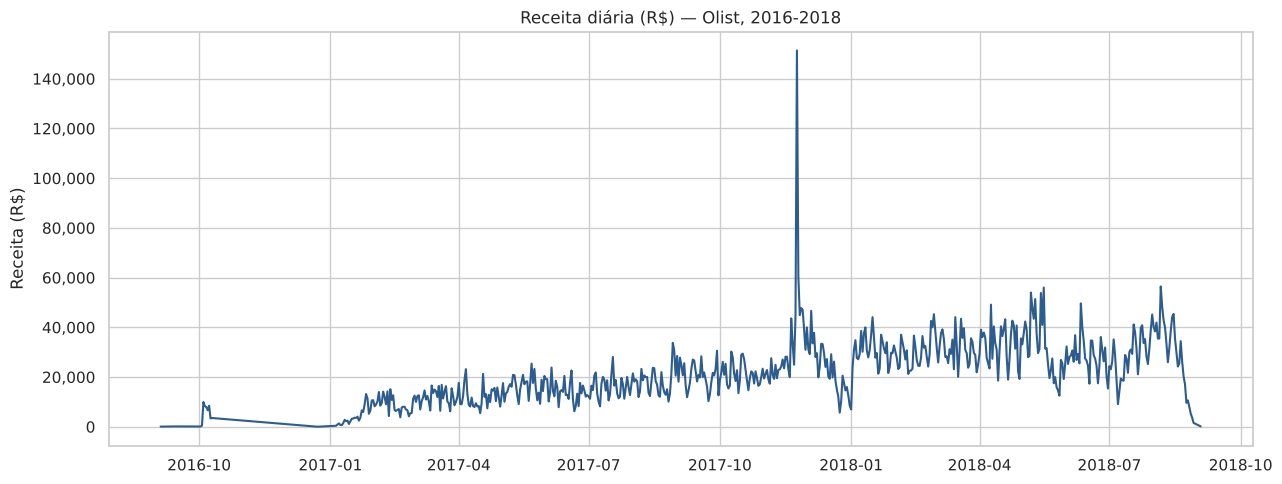

,dia,pedidos,receita
336,2017-11-24,1156,"151,384.19"
337,2017-11-25,492,"60,343.76"
591,2018-08-06,372,"56,427.39"
509,2018-05-16,354,"56,004.03"
500,2018-05-07,368,"53,990.68"


In [ ]:
vendas_dia = (
    itens.merge(base[['order_id', 'order_purchase_timestamp']].drop_duplicates('order_id'),
                on='order_id', how='left')
    .assign(dia=lambda d: d['order_purchase_timestamp'].dt.date)
    .groupby('dia')
    .agg(pedidos=('order_id', 'nunique'), receita=('price', 'sum'))
    .reset_index()
)
vendas_dia['dia'] = pd.to_datetime(vendas_dia['dia'])

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.plot(vendas_dia['dia'], vendas_dia['receita'], color='#2d5c8e')
ax1.set_title('Receita diária (R$) — Olist, 2016-2018')
ax1.set_ylabel('Receita (R$)')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

vendas_dia.sort_values('receita', ascending=False).head(5)


O pico isolado de receita coincide com a Black Friday de 2017 (24/11) confirmando sazonalidade
comercial real no dataset, não apenas ruído.

### 6.2 Receita e volume por categoria de produto

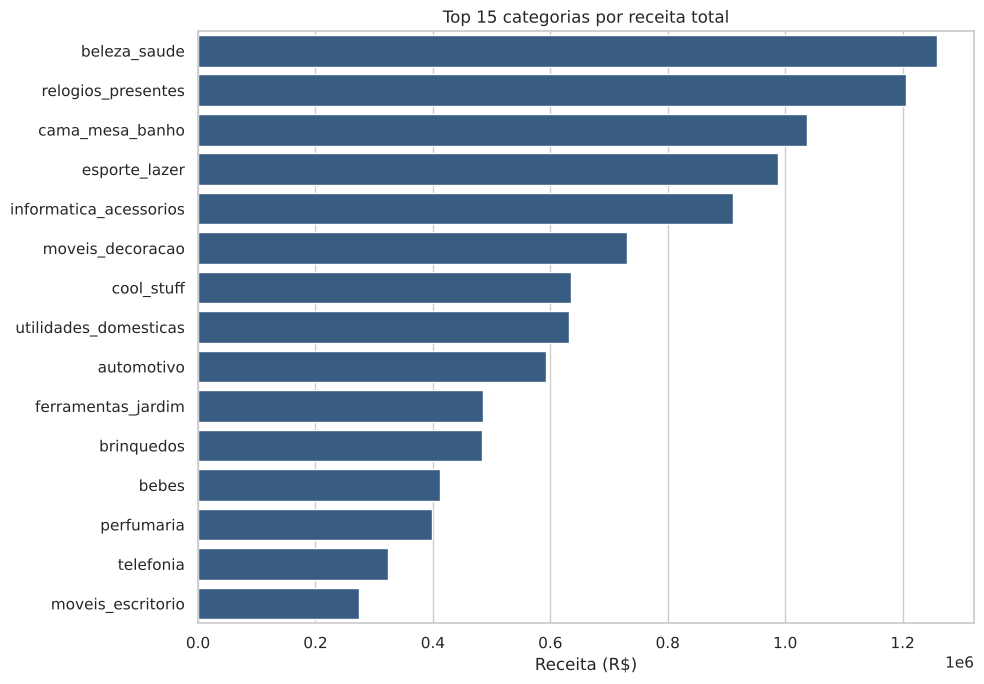

In [ ]:
receita_categoria = (
    itens.groupby('product_category_name')
    .agg(receita_total=('price', 'sum'), qtd_itens=('order_item_id', 'count'))
    .sort_values('receita_total', ascending=False)
)

top15 = receita_categoria.head(15)

plt.figure(figsize=(10, 7))
sns.barplot(x=top15['receita_total'], y=top15.index, color='#2d5c8e')
plt.title('Top 15 categorias por receita total')
plt.xlabel('Receita (R$)')
plt.ylabel('')
plt.tight_layout()
plt.show()


As categorias `beleza_saude` e `relogios_presentes` são as com maior receita no dataset.

### 6.3 Distribuição geográfica de clientes e vendedores

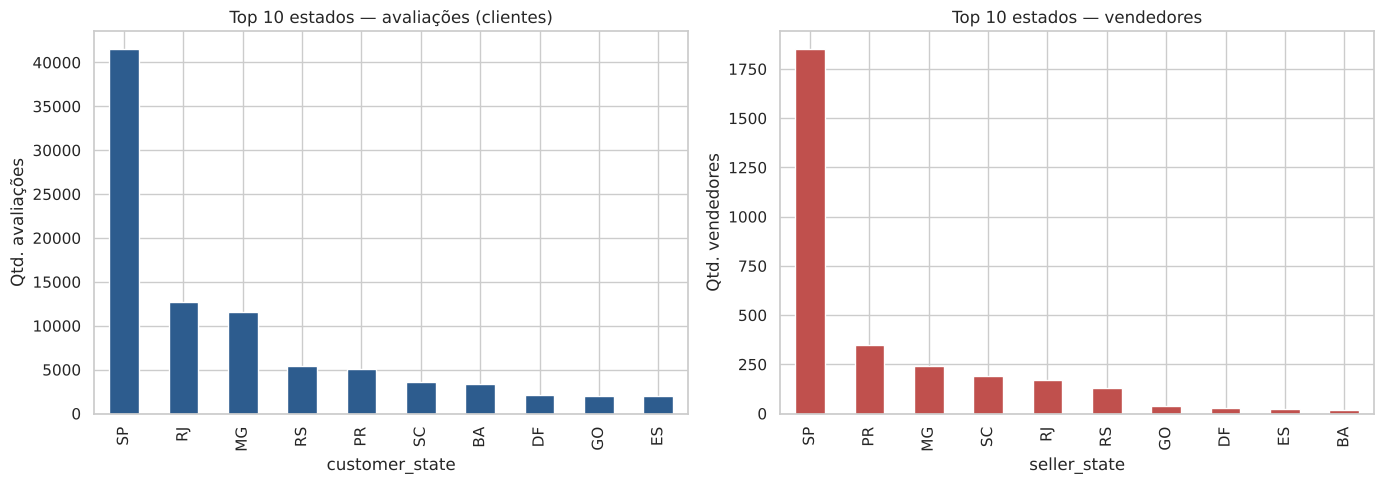

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

base['customer_state'].value_counts().head(10).plot(kind='bar', ax=axes[0], color='#2d5c8e')
axes[0].set_title('Top 10 estados — avaliações (clientes)')
axes[0].set_ylabel('Qtd. avaliações')

sellers['seller_state'].value_counts().head(10).plot(kind='bar', ax=axes[1], color='#c0504d')
axes[1].set_title('Top 10 estados — vendedores')
axes[1].set_ylabel('Qtd. vendedores')

plt.tight_layout()
plt.show()


SP concentra a maior parte de clientes e, principalmente, vendedores<br>
Relevante para o RAG:
perguntas sobre "reclamações por região" fora do eixo SP/RJ/MG terão amostra pequena, e a resposta
precisa refletir essa limitação (não inventar padrão regional sem base suficiente).

### 6.4 Formas de pagamento

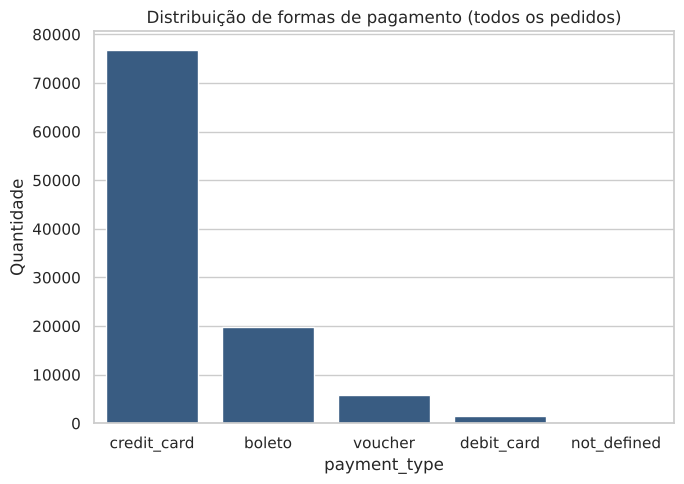

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [ ]:
# Direto da tabela payments
pay_counts = payments['payment_type'].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=pay_counts.index, y=pay_counts.values, color='#2d5c8e')
plt.title('Distribuição de formas de pagamento (todos os pedidos)')
plt.ylabel('Quantidade')
plt.tight_layout()
plt.show()

pay_counts


`Cartão de crédito` segue sendo a forma de pagamento mais utilizado no dataset.

### 6.5 Prazo de entrega: estimado vs real, e relação com a nota

In [ ]:
base_entrega = base.dropna(subset=['dias_atraso', 'review_score']).copy()

print(f"% de pedidos avaliados com entrega atrasada: {base_entrega['entregue_com_atraso'].mean()*100:.2f}%")
print()
print("Nota média por situação de entrega:")
print(base_entrega.groupby('entregue_com_atraso')['review_score'].mean().round(2))


% de pedidos avaliados com entrega atrasada: 8.00%

Nota média por situação de entrega:
entregue_com_atraso
False   4.29
True    2.57
Name: review_score, dtype: float64


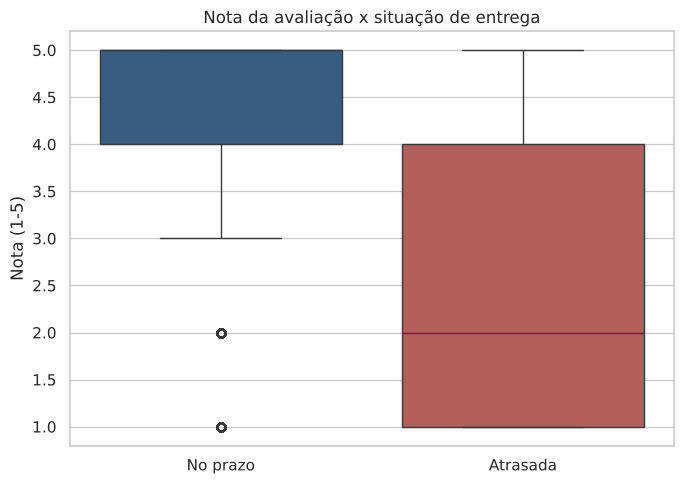

In [ ]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=base_entrega, x='entregue_com_atraso', y='review_score', hue='entregue_com_atraso',
            palette=['#2d5c8e', '#c0504d'], legend=False)
plt.xticks([0, 1], ['No prazo', 'Atrasada'])
plt.title('Nota da avaliação x situação de entrega')
plt.xlabel('')
plt.ylabel('Nota (1-5)')
plt.tight_layout()
plt.show()


Entregas atrasadas tem nota média visivelmente mais baixa, confirma `entregue_com_atraso` e
`dias_atraso` como metadados de altíssimo valor para filtrar perguntas no RAG sobre insatisfação.

## 7. EDA textual das reviews (sobre a base do RAG)

Esta é a seção mais importante para o RAG: entender o texto (`rag['texto']`) que será transformado em
embeddings.

### 7.1 Distribuição de notas e de presença de texto (base completa x base do RAG)

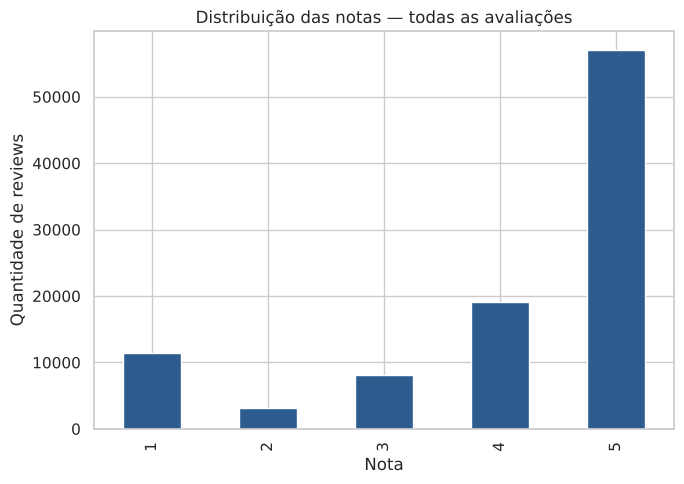

Base completa: {1: 11.52, 2: 3.17, 3: 8.24, 4: 19.29, 5: 57.77}
Base do RAG:   {1: 23.48, 2: 5.78, 3: 9.12, 4: 14.02, 5: 47.6}


In [ ]:
plt.figure(figsize=(7, 5))
base['review_score'].value_counts().sort_index().plot(kind='bar', color='#2d5c8e')
plt.title('Distribuição das notas — todas as avaliações')
plt.xlabel('Nota')
plt.ylabel('Quantidade de reviews')
plt.tight_layout()
plt.show()

print("Base completa:", base['review_score'].value_counts(normalize=True).sort_index().mul(100).round(2).to_dict())
print("Base do RAG:  ", rag['nota'].value_counts(normalize=True).sort_index().mul(100).round(2).to_dict())


**Achado crítico para o RAG:** a proporção de reviews com texto varia por nota, notas 1 e 5
(opiniões mais extremas) geram mais texto espontâneo que notas intermediárias. A base do RAG é
**naturalmente desbalanceada** em relação à base completa.

### 7.2 Limpeza textual para análise de linguagem (stopwords e normalização)

Documentos do RAG sem conteúdo útil após limpeza para NLP: 13 (0.04%)


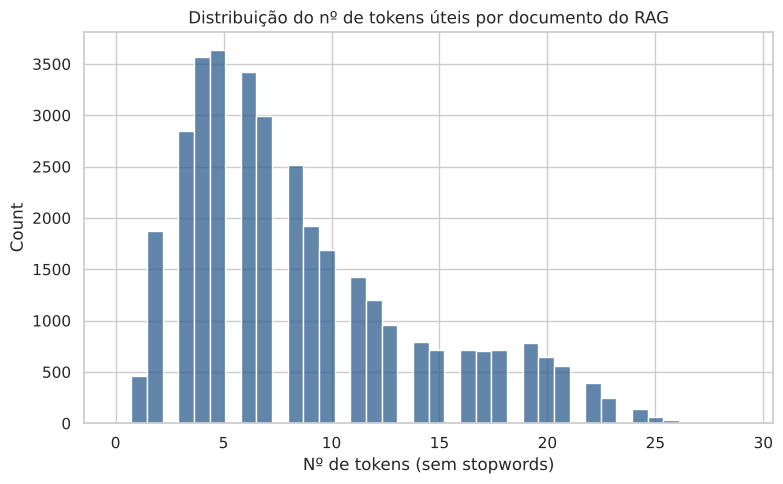

count   35,027.00
mean         8.61
std          5.46
min          0.00
25%          4.00
50%          7.00
75%         11.00
max         29.00
Name: n_tokens, dtype: float64

In [ ]:
# Lista de stopwords em português (definida localmente — evita dependência de download externo,
# robusto para rodar tanto aqui quanto no Google Colab sem precisar de nltk.download)
STOPWORDS_PT = set('''
a ao aos aquela aquelas aquele aqueles aquilo as até com como da das de dela
delas dele deles depois do dos e ela elas ele eles em entre era eram essa
essas esse esses esta estas este estes eu foi fomos for foram fosse fui
há isso isto já lhe lhes mais mas me mesmo meu meus minha minhas muito na
nas nem no nos nossa nossas nosso nossos num numa não nós o os ou para
pela pelas pelo pelos por qual quando que quem se seu seus só sua suas
também te tem tendo tenho ter teu teus teve tinha tive to toda todas todo
todos tu tua tuas um uma você vocês vos à às é ja pra pro pq tb ta tava
'''.split())

def normalizar_para_nlp(texto):
    if pd.isna(texto):
        return ""
    texto = str(texto).lower()
    texto = unicodedata.normalize('NFKD', texto).encode('ascii', 'ignore').decode('utf-8')
    texto = re.sub(r'[^a-z0-9\s]', ' ', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()
    return texto

def tokenizar_sem_stopwords(texto_limpo):
    tokens = texto_limpo.split()
    return [t for t in tokens if t not in STOPWORDS_PT and len(t) > 2]

rag['texto_limpo_nlp'] = rag['texto'].apply(normalizar_para_nlp)
rag['tokens'] = rag['texto_limpo_nlp'].apply(tokenizar_sem_stopwords)
rag['n_tokens'] = rag['tokens'].apply(len)

vazio_pos_limpeza = (rag['n_tokens'] == 0).sum()
print(f"Documentos do RAG sem conteúdo útil após limpeza para NLP: {vazio_pos_limpeza:,} "
      f"({vazio_pos_limpeza/len(rag)*100:.2f}%)")

plt.figure(figsize=(8,5))
sns.histplot(rag['n_tokens'], bins=40, color='#2d5c8e')
plt.title('Distribuição do nº de tokens úteis por documento do RAG')
plt.xlabel('Nº de tokens (sem stopwords)')
plt.tight_layout()
plt.show()

rag['n_tokens'].describe()


### 7.3 Comprimento do texto por nota

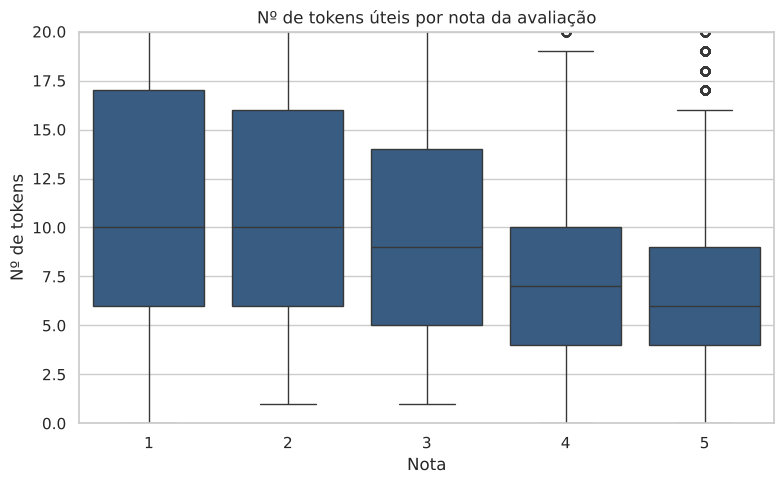

nota
1   10.00
2   10.00
3    9.00
4    7.00
5    6.00
Name: n_tokens, dtype: float64

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=rag, x='nota', y='n_tokens', color='#2d5c8e')
plt.title('Nº de tokens úteis por nota da avaliação')
plt.xlabel('Nota')
plt.ylabel('Nº de tokens')
plt.ylim(0, rag['n_tokens'].quantile(0.95))
plt.tight_layout()
plt.show()

rag.groupby('nota')['n_tokens'].median()


### 7.4 Nuvens de palavras — avaliações negativas x positivas

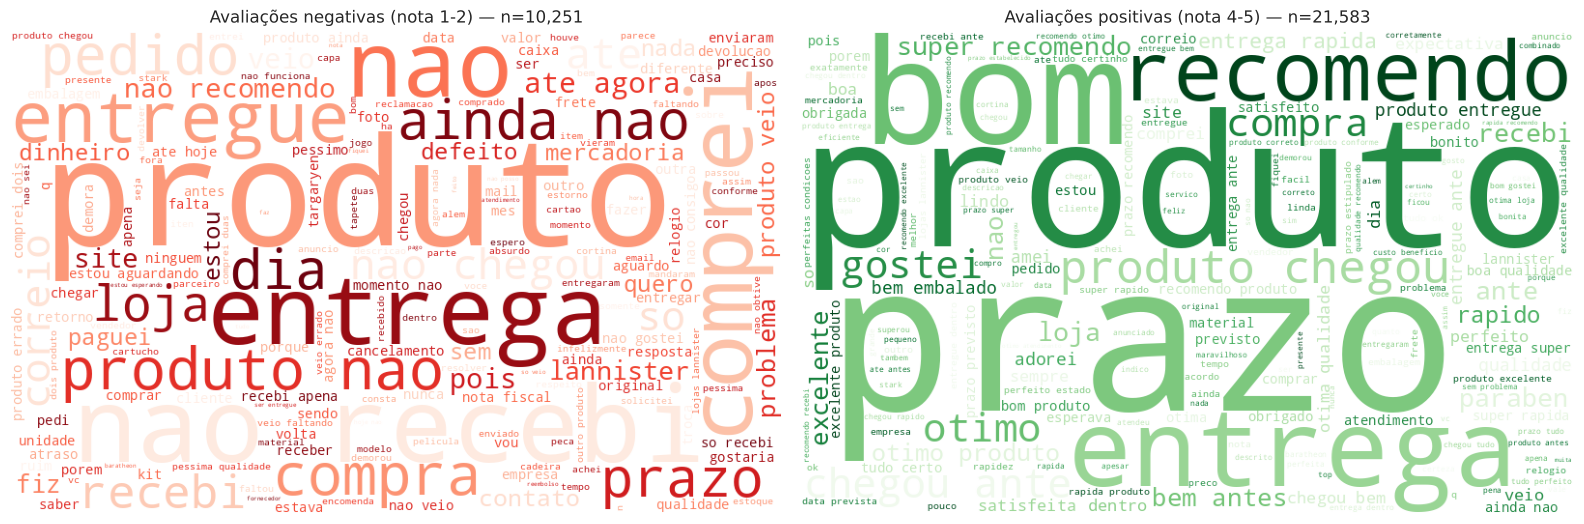

In [ ]:
neg = rag[rag['nota'] <= 2]
pos = rag[rag['nota'] >= 4]

texto_neg = ' '.join(neg['texto_limpo_nlp'])
texto_pos = ' '.join(pos['texto_limpo_nlp'])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

wc_neg = WordCloud(width=800, height=500, background_color='white',
                    colormap='Reds', stopwords=STOPWORDS_PT).generate(texto_neg)
axes[0].imshow(wc_neg)
axes[0].set_title(f'Avaliações negativas (nota 1-2) — n={len(neg):,}')
axes[0].axis('off')

wc_pos = WordCloud(width=800, height=500, background_color='white',
                    colormap='Greens', stopwords=STOPWORDS_PT).generate(texto_pos)
axes[1].imshow(wc_pos)
axes[1].set_title(f'Avaliações positivas (nota 4-5) — n={len(pos):,}')
axes[1].axis('off')

plt.tight_layout()
plt.show()


### 7.5 Bigramas mais frequentes — negativas x positivas

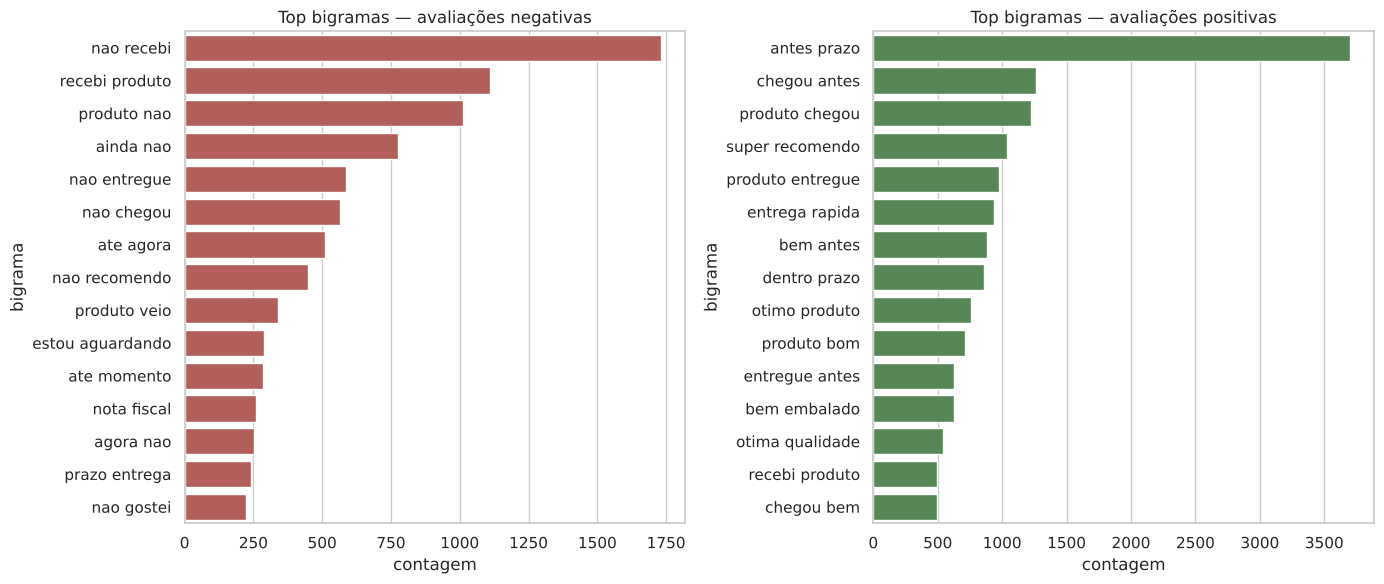

In [ ]:
def top_ngrams(lista_de_tokens, n=2, top=15):
    contador = Counter()
    for tokens in lista_de_tokens:
        ngramas = zip(*[tokens[i:] for i in range(n)])
        contador.update(' '.join(g) for g in ngramas)
    return contador.most_common(top)

bigramas_neg = top_ngrams(neg['tokens'], n=2, top=15)
bigramas_pos = top_ngrams(pos['tokens'], n=2, top=15)

df_big_neg = pd.DataFrame(bigramas_neg, columns=['bigrama', 'contagem'])
df_big_pos = pd.DataFrame(bigramas_pos, columns=['bigrama', 'contagem'])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=df_big_neg, x='contagem', y='bigrama', color='#c0504d', ax=axes[0])
axes[0].set_title('Top bigramas — avaliações negativas')

sns.barplot(data=df_big_pos, x='contagem', y='bigrama', color='#4f8f4f', ax=axes[1])
axes[1].set_title('Top bigramas — avaliações positivas')

plt.tight_layout()
plt.show()


**Leitura dos achados textuais:** entrega (prazo, atraso, transportadora) domina tanto elogios
quanto reclamações. Reforça a decisão da Seção 6.5: `entregue_com_atraso`/`dias_atraso` são metadados
de altíssimo valor. Grande parte das perguntas de negócio sobre insatisfação vão gravitar em torno de
logística.

## 8. Conclusões e decisões para a etapa de RAG

### Principais achados
1. **Volume e período**: ~100k pedidos (2016-2018), com pico claro na Black Friday de 2017.
2. **Concentração geográfica**: clientes e vendedores concentrados em SP/RJ/MG, fora desse eixo temos uma amostra pequena.
3. **Qualidade dos dados**: sem inconsistências graves de data/preço/nota; poucos produtos sem
   categoria (tratados como "sem_categoria"); geolocation precisou de agregação por CEP para não
   multiplicar linhas no merge.
4. **Cobertura de texto**: a base completa tem 98.673 avaliações; só 42,1% têm comentário utilizável, e
   após remover textos idênticos a base do RAG final fica com **35.027 documentos únicos**.
5. **Entrega é o fator dominante**: tanto estatisticamente (nota média cai com atraso) quanto
   textualmente (bigramas de entrega dominam elogios e reclamações).

### Arquivos gerados (em `data/processed/`)
| Arquivo | Conteúdo | Linhas |
|---|---|---|
| `base_avaliacoes_completa.csv` | Todas as avaliações (com e sem comentário), já com metadados de pedido, cliente, geolocalização e categoria | 98.673 |
| `base_rag.csv` | Só avaliações com comentário de texto útil e sem duplicidade literal, pronta para virar documentos do RAG | 35.027 |

### Decisões para a construção da base do RAG
- **Granularidade**: `base_rag.csv`, grão de **review única por pedido** (deduplicada por `order_id`
  e por texto idêntico, com a frequência guardada em `n_ocorrencias`).
- **Texto do documento**: coluna `texto` (`doc_id` = `order_id`), já concatenando título + mensagem.
- **Metadados a carregar junto de cada embedding** (exatamente os de `base_rag.csv`): `nota`,
  `order_status`, `data_compra`, `tempo_entrega_dias`, `dias_atraso`, `entregue_com_atraso`,
  `customer_state`, `customer_city`, `geo_lat`, `geo_lng`, `categoria_principal`, `categorias`,
  `n_itens`, `n_ocorrencias`. Cobrem os principais eixos de pergunta esperados (categoria, região,
  nota, logística, recorrência do comentário).
- **Atenção na avaliação do RAG**: dado o desbalanceamento de texto por nota e a concentração
  geográfica em poucos estados, o sistema deve avisar quando a evidência disponível for escassa para
  um recorte específico, em vez de generalizar com poucos dados.

**Próximo passo:** construção do pipeline RAG a partir de `base_rag.csv` (embeddings multilíngues →
banco vetorial com os metadados acima → geração de resposta com controle de confiança).